In [2]:
import sys
sys.path.append('..')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import shap
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from src.models.classifier import SignalClassifier

print("All imports successful!")

All imports successful!


In [3]:
with open('../data/processed/ticker_list.txt', 'r') as f:
    all_tickers = [line.strip() for line in f.readlines()]

bank_tickers = ['NABIL', 'NICA', 'HBL', 'ADBL', 'EBL', 
                'SCB', 'SBI', 'SANIMA', 'GBIME', 'NBL',
                'NIMB', 'CZBIL', 'MBL', 'PCBL', 'NMB',
                'PRVU', 'SRBL', 'LXBL', 'KBL']

dfs = []
for ticker in bank_tickers:
    try:
        df = pd.read_csv(f'../data/processed/{ticker}_features.csv')
        dfs.append(df)
    except:
        pass

data = pd.concat(dfs, ignore_index=True)
print(f"Total rows: {len(data)}")
print(f"Stocks loaded: {data['Ticker'].nunique()}")
print(f"\nLabel distribution:")
print(data['Label'].value_counts())
print(f"\nDate range: {data['Date'].min()} to {data['Date'].max()}")

Total rows: 50189
Stocks loaded: 17

Label distribution:
Label
1    26853
0    12176
2    11160
Name: count, dtype: int64

Date range: 2007-12-27 to 2026-06-25


In [4]:
drop_cols = ['Date', 'Open', 'High', 'Low', 'Close', 'Volume',
             'Trades', 'Turnover', 'Ticker', 'Label', 'Future_Return', 'Sector']
feature_cols = [c for c in data.columns if c not in drop_cols]

data = data.dropna(subset=feature_cols + ['Label'])
X = data[feature_cols]
y = data['Label']

print(f"Features: {feature_cols}")
print(f"Total features: {len(feature_cols)}")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f"\nTrain: {len(X_train)} rows")
print(f"Test:  {len(X_test)} rows")

# Load saved model
clf = SignalClassifier.load('../data/models/Commercial_Banks_model.pkl')
print("\nModel loaded successfully!")
print(f"Model type: {clf.model_type}")

Features: ['SMA_7', 'SMA_21', 'SMA_50', 'EMA_12', 'EMA_26', 'MACD', 'MACD_Signal', 'RSI_14', 'Stoch', 'BB_High', 'BB_Low', 'BB_Width', 'ATR', 'Volume_Change', 'OBV', 'Close_lag_1', 'Return_lag_1', 'Close_lag_3', 'Return_lag_3', 'Close_lag_5', 'Return_lag_5', 'Close_lag_10', 'Return_lag_10']
Total features: 23

Train: 39484 rows
Test:  9872 rows

Model loaded successfully!
Model type: lightgbm


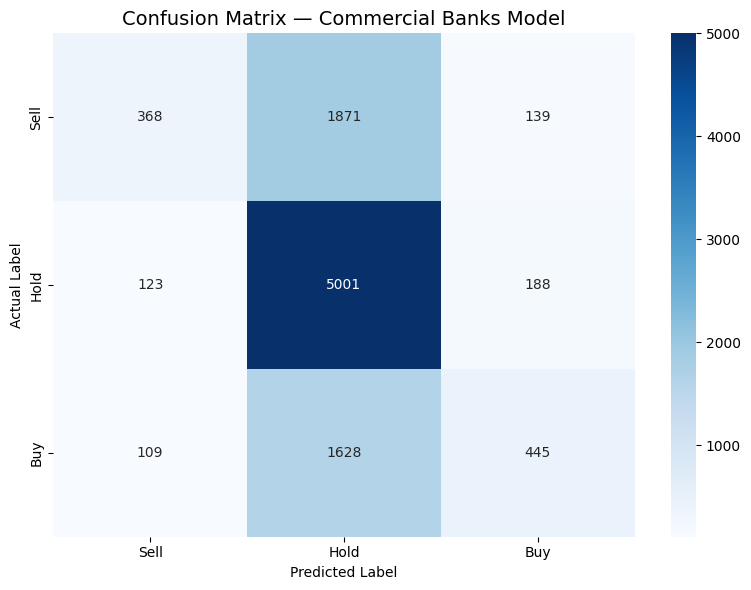


Classification Report:
              precision    recall  f1-score   support

        Sell       0.61      0.15      0.25      2378
        Hold       0.59      0.94      0.72      5312
         Buy       0.58      0.20      0.30      2182

    accuracy                           0.59      9872
   macro avg       0.59      0.43      0.42      9872
weighted avg       0.59      0.59      0.52      9872



In [5]:
preds = clf.model.predict(X_test)
label_names = ['Sell', 'Hold', 'Buy']

# Plot confusion matrix
plt.figure(figsize=(8, 6))
cm = confusion_matrix(y_test, preds)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=label_names,
            yticklabels=label_names)
plt.title('Confusion Matrix — Commercial Banks Model', fontsize=14)
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.tight_layout()
plt.show()

# Print classification report
print("\nClassification Report:")
print(classification_report(y_test, preds, target_names=label_names))

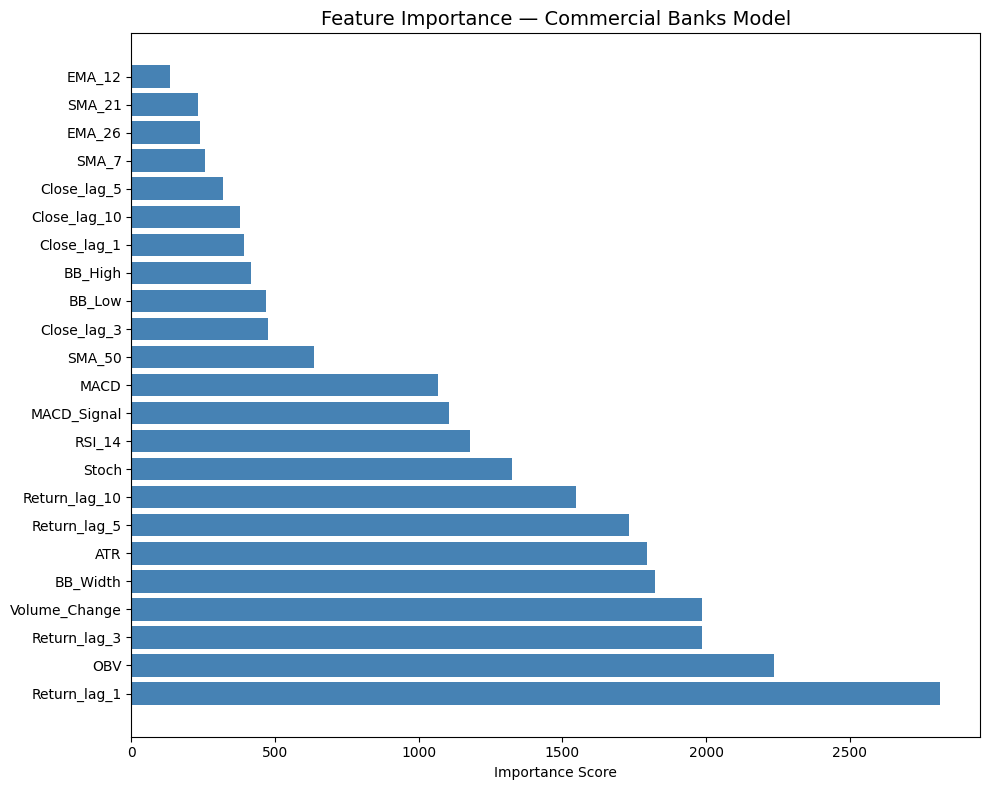


Top 5 most important features:
      Feature  Importance
 Return_lag_1        2813
          OBV        2237
 Return_lag_3        1986
Volume_Change        1986
     BB_Width        1821


In [6]:
import lightgbm as lgb

# Get feature importance
importance = pd.DataFrame({
    'Feature': feature_cols,
    'Importance': clf.model.feature_importances_
}).sort_values('Importance', ascending=False)

# Plot
plt.figure(figsize=(10, 8))
plt.barh(importance['Feature'], importance['Importance'], color='steelblue')
plt.title('Feature Importance — Commercial Banks Model', fontsize=14)
plt.xlabel('Importance Score')
plt.tight_layout()
plt.show()

print("\nTop 5 most important features:")
print(importance.head(5)[['Feature', 'Importance']].to_string(index=False))

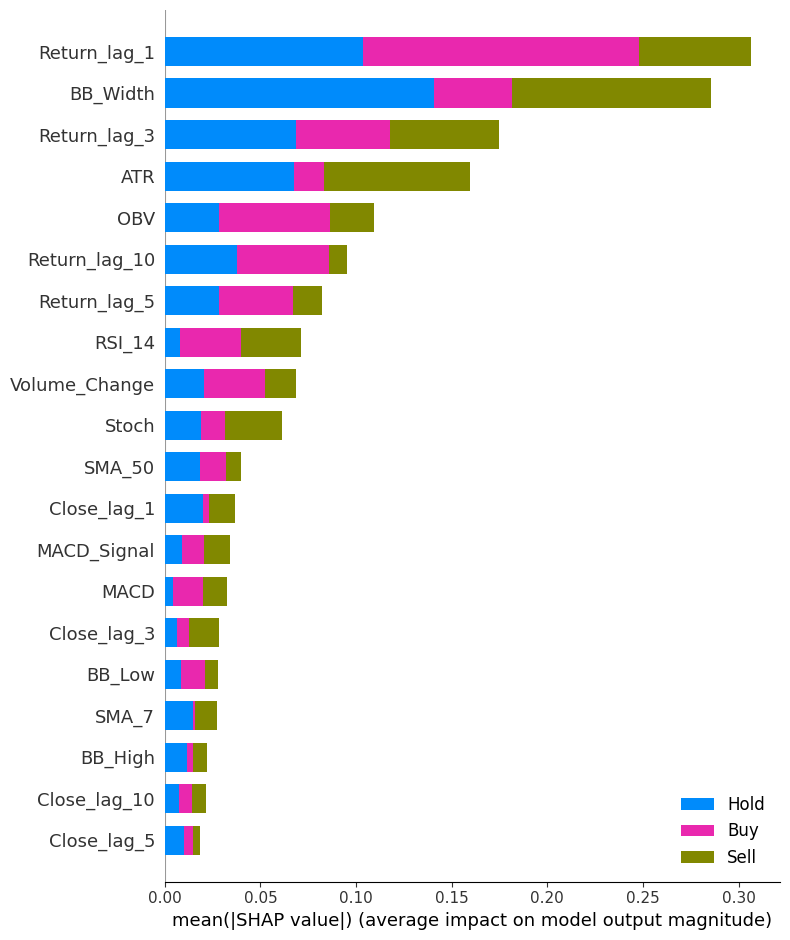

In [7]:
# SHAP explanation for the model
explainer = shap.TreeExplainer(clf.model)
shap_values = explainer.shap_values(X_test)

# Summary plot — shows impact of each feature on predictions
shap.summary_plot(shap_values, X_test, 
                  class_names=['Sell', 'Hold', 'Buy'],
                  feature_names=feature_cols,
                  plot_type='bar')

NABIL Signal: Hold
Confidence: 87.9%
Probabilities: {'Sell': 0.051192306122355244, 'Hold': 0.8790618929993769, 'Buy': 0.06974580087826798}


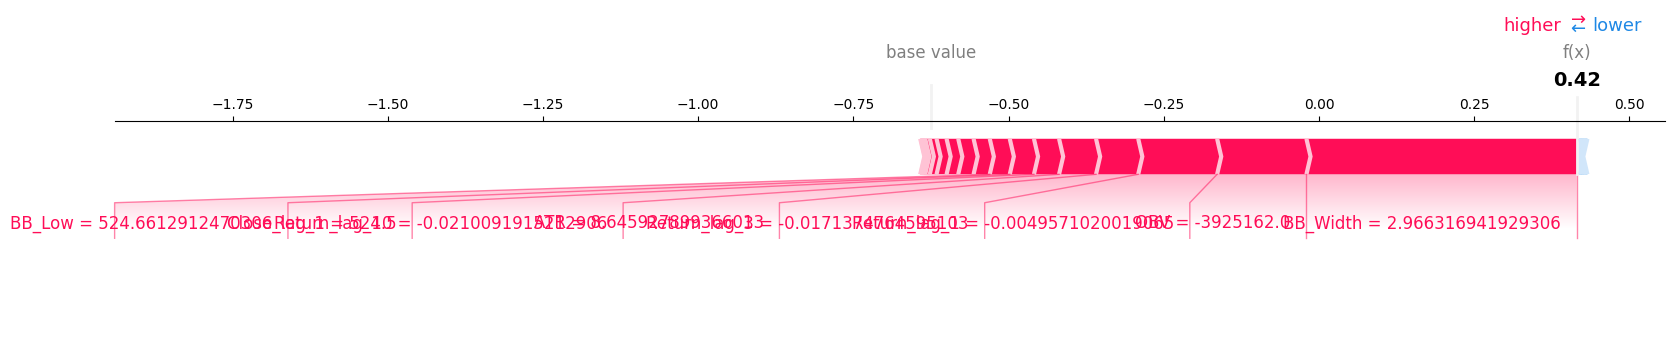

In [8]:
# Explain one prediction for NABIL (latest data point)
nabil = pd.read_csv('../data/processed/NABIL_features.csv')
nabil = nabil.dropna(subset=feature_cols)
latest = nabil[feature_cols].tail(1)

# Get prediction
result = clf.predict(latest)
print(f"NABIL Signal: {result['signal']}")
print(f"Confidence: {result['confidence']*100:.1f}%")
print(f"Probabilities: {result['probabilities']}")

# SHAP force plot for this prediction
shap.initjs()
explainer2 = shap.TreeExplainer(clf.model)
shap_vals = explainer2.shap_values(latest)

# Show which features pushed toward the predicted signal
label_idx = {'Sell': 0, 'Hold': 1, 'Buy': 2}
pred_idx = label_idx[result['signal']]

shap.force_plot(
    explainer2.expected_value[pred_idx],
    shap_vals[pred_idx],
    latest,
    matplotlib=True,
    show=True
)

In [9]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report

# ── 1. Prepare Commercial Banks data ────────────────────────
bank_tickers = ['NABIL', 'NICA', 'HBL', 'ADBL', 'EBL', 
                'SCB', 'SBI', 'SANIMA', 'GBIME', 'NBL',
                'NIMB', 'CZBIL', 'MBL', 'PCBL', 'NMB',
                'PRVU', 'SRBL', 'LXBL', 'KBL']

dfs = []
for ticker in bank_tickers:
    try:
        df = pd.read_csv(f'../data/processed/{ticker}_features.csv')
        dfs.append(df)
    except:
        pass

nn_data = pd.concat(dfs, ignore_index=True)
nn_data['Date'] = pd.to_datetime(nn_data['Date'])
nn_data = nn_data[nn_data['Date'] >= pd.Timestamp('2024-01-01')]
nn_data = nn_data.dropna(subset=feature_cols + ['Label'])

X_nn = nn_data[feature_cols].values
y_nn = nn_data['Label'].values

# ── 2. Scale features ────────────────────────────────────────
scaler = StandardScaler()
X_nn = scaler.fit_transform(X_nn)

# ── 3. Train/test split ──────────────────────────────────────
X_train_nn, X_test_nn, y_train_nn, y_test_nn = train_test_split(
    X_nn, y_nn, test_size=0.2, random_state=42, stratify=y_nn
)

# Convert to tensors
X_train_t = torch.FloatTensor(X_train_nn)
y_train_t = torch.LongTensor(y_train_nn)
X_test_t  = torch.FloatTensor(X_test_nn)
y_test_t  = torch.LongTensor(y_test_nn)

train_ds = TensorDataset(X_train_t, y_train_t)
train_dl = DataLoader(train_ds, batch_size=64, shuffle=True)

print(f"Train: {len(X_train_nn)} | Test: {len(X_test_nn)}")
print(f"Features: {X_nn.shape[1]}")

Train: 7724 | Test: 1932
Features: 23


In [12]:
# ── 4. Define Neural Network ─────────────────────────────────
class StockNN(nn.Module):
    def __init__(self, input_dim):
        super(StockNN, self).__init__()
        self.network = nn.Sequential(
            # Layer 1
            nn.Linear(input_dim, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.3),
            
            # Layer 2
            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(0.3),
            
            # Layer 3
            nn.Linear(64, 32),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.Dropout(0.2),
            
            # Output layer (3 classes: Sell, Hold, Buy)
            nn.Linear(32, 3)
        )
    
    def forward(self, x):
        return self.network(x)

# ── 5. Train the model ───────────────────────────────────────
model = StockNN(input_dim=X_nn.shape[1])
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=0.5)

epochs = 100
train_losses = []

for epoch in range(epochs):
    model.train()
    epoch_loss = 0
    
    for X_batch, y_batch in train_dl:
        optimizer.zero_grad()
        outputs = model(X_batch)
        loss = criterion(outputs, y_batch)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()
    
    scheduler.step()
    avg_loss = epoch_loss / len(train_dl)
    train_losses.append(avg_loss)
    
    if (epoch + 1) % 10 == 0:
        print(f"Epoch {epoch+1}/{epochs} | Loss: {avg_loss:.4f}")

print("\nTraining complete!")

# ── 6. Evaluate ──────────────────────────────────────────────
model.eval()
with torch.no_grad():
    outputs = model(X_test_t)
    _, predicted = torch.max(outputs, 1)
    preds_nn = predicted.numpy()

acc_nn = accuracy_score(y_test_nn, preds_nn)
print(f"\nNeural Network Accuracy: {acc_nn*100:.1f}%")
print(f"LightGBM Accuracy:       61.1%")
print("\nClassification Report:")
print(classification_report(y_test_nn, preds_nn, target_names=['Sell', 'Hold', 'Buy']))

Epoch 10/100 | Loss: 0.8862
Epoch 20/100 | Loss: 0.8752
Epoch 30/100 | Loss: 0.8711
Epoch 40/100 | Loss: 0.8646
Epoch 50/100 | Loss: 0.8666
Epoch 60/100 | Loss: 0.8642
Epoch 70/100 | Loss: 0.8658
Epoch 80/100 | Loss: 0.8601
Epoch 90/100 | Loss: 0.8654
Epoch 100/100 | Loss: 0.8633

Training complete!

Neural Network Accuracy: 63.3%
LightGBM Accuracy:       61.1%

Classification Report:
              precision    recall  f1-score   support

        Sell       0.49      0.20      0.28       409
        Hold       0.66      0.92      0.77      1157
         Buy       0.53      0.19      0.28       366

    accuracy                           0.63      1932
   macro avg       0.56      0.44      0.45      1932
weighted avg       0.60      0.63      0.57      1932



In [13]:
# ── Improved Neural Network ──────────────────────────────────
class StockNNv2(nn.Module):
    def __init__(self, input_dim):
        super(StockNNv2, self).__init__()
        self.network = nn.Sequential(
            # Layer 1
            nn.Linear(input_dim, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(0.3),

            # Layer 2
            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.3),

            # Layer 3
            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(0.2),

            # Layer 4
            nn.Linear(64, 32),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.Dropout(0.2),

            # Output
            nn.Linear(32, 3)
        )

    def forward(self, x):
        return self.network(x)

# Train
model_v2 = StockNNv2(input_dim=X_nn.shape[1])
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model_v2.parameters(), lr=0.0005, weight_decay=1e-4)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=100)

epochs = 200
train_losses_v2 = []

for epoch in range(epochs):
    model_v2.train()
    epoch_loss = 0

    for X_batch, y_batch in train_dl:
        optimizer.zero_grad()
        outputs = model_v2(X_batch)
        loss = criterion(outputs, y_batch)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()

    scheduler.step()
    avg_loss = epoch_loss / len(train_dl)
    train_losses_v2.append(avg_loss)

    if (epoch + 1) % 20 == 0:
        print(f"Epoch {epoch+1}/{epochs} | Loss: {avg_loss:.4f}")

print("\nTraining complete!")

# Evaluate
model_v2.eval()
with torch.no_grad():
    outputs = model_v2(X_test_t)
    _, predicted = torch.max(outputs, 1)
    preds_v2 = predicted.numpy()

acc_v2 = accuracy_score(y_test_nn, preds_v2)
print(f"\nNN v2 Accuracy:    {acc_v2*100:.1f}%")
print(f"NN v1 Accuracy:    63.3%")
print(f"LightGBM Accuracy: 61.1%")
print("\nClassification Report:")
print(classification_report(y_test_nn, preds_v2, target_names=['Sell', 'Hold', 'Buy']))

Epoch 20/200 | Loss: 0.8748
Epoch 40/200 | Loss: 0.8585
Epoch 60/200 | Loss: 0.8448
Epoch 80/200 | Loss: 0.8295
Epoch 100/200 | Loss: 0.8322
Epoch 120/200 | Loss: 0.8291
Epoch 140/200 | Loss: 0.8270
Epoch 160/200 | Loss: 0.8348
Epoch 180/200 | Loss: 0.8228
Epoch 200/200 | Loss: 0.8165

Training complete!

NN v2 Accuracy:    64.6%
NN v1 Accuracy:    63.3%
LightGBM Accuracy: 61.1%

Classification Report:
              precision    recall  f1-score   support

        Sell       0.57      0.23      0.33       409
        Hold       0.67      0.92      0.77      1157
         Buy       0.53      0.26      0.35       366

    accuracy                           0.65      1932
   macro avg       0.59      0.47      0.48      1932
weighted avg       0.62      0.65      0.60      1932



In [14]:
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

def objective(trial):
    # Hyperparameters to tune
    n_layers = trial.suggest_int('n_layers', 2, 4)
    dropout = trial.suggest_float('dropout', 0.1, 0.5)
    lr = trial.suggest_float('lr', 1e-4, 1e-2, log=True)
    weight_decay = trial.suggest_float('weight_decay', 1e-5, 1e-3, log=True)
    batch_size = trial.suggest_categorical('batch_size', [32, 64, 128])
    
    # Build dynamic network
    layers = []
    input_dim = X_nn.shape[1]
    hidden_sizes = [256, 128, 64, 32]
    
    for i in range(n_layers):
        out_dim = hidden_sizes[i]
        layers.extend([
            nn.Linear(input_dim, out_dim),
            nn.BatchNorm1d(out_dim),
            nn.ReLU(),
            nn.Dropout(dropout)
        ])
        input_dim = out_dim
    
    layers.append(nn.Linear(input_dim, 3))
    model_trial = nn.Sequential(*layers)
    
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model_trial.parameters(), 
                          lr=lr, 
                          weight_decay=weight_decay)
    
    # DataLoader with trial batch size
    train_ds_trial = TensorDataset(X_train_t, y_train_t)
    train_dl_trial = DataLoader(train_ds_trial, 
                               batch_size=batch_size, 
                               shuffle=True)
    
    # Train for 30 epochs per trial
    model_trial.train()
    for epoch in range(30):
        for X_batch, y_batch in train_dl_trial:
            optimizer.zero_grad()
            outputs = model_trial(X_batch)
            loss = criterion(outputs, y_batch)
            loss.backward()
            optimizer.step()
    
    # Evaluate
    model_trial.eval()
    with torch.no_grad():
        outputs = model_trial(X_test_t)
        _, predicted = torch.max(outputs, 1)
        acc = accuracy_score(y_test_nn, predicted.numpy())
    
    return acc

# Run Optuna
print("Running Optuna hyperparameter search (20 trials)...")
study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=20)

print(f"\nBest accuracy: {study.best_value*100:.1f}%")
print(f"Best params: {study.best_params}")

Running Optuna hyperparameter search (20 trials)...

Best accuracy: 65.5%
Best params: {'n_layers': 3, 'dropout': 0.14880580988439468, 'lr': 0.0004129240945486906, 'weight_decay': 2.7472127874114825e-05, 'batch_size': 128}


In [15]:
# ── Final model with Optuna best params ─────────────────────
best = study.best_params

# Build best network
layers = []
input_dim = X_nn.shape[1]
hidden_sizes = [256, 128, 64, 32]

for i in range(best['n_layers']):
    out_dim = hidden_sizes[i]
    layers.extend([
        nn.Linear(input_dim, out_dim),
        nn.BatchNorm1d(out_dim),
        nn.ReLU(),
        nn.Dropout(best['dropout'])
    ])
    input_dim = out_dim

layers.append(nn.Linear(input_dim, 3))
model_final = nn.Sequential(*layers)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model_final.parameters(),
                       lr=best['lr'],
                       weight_decay=best['weight_decay'])
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=200)

train_dl_final = DataLoader(
    TensorDataset(X_train_t, y_train_t),
    batch_size=best['batch_size'],
    shuffle=True
)

# Train for 200 epochs with best params
epochs = 200
train_losses_final = []

for epoch in range(epochs):
    model_final.train()
    epoch_loss = 0
    for X_batch, y_batch in train_dl_final:
        optimizer.zero_grad()
        outputs = model_final(X_batch)
        loss = criterion(outputs, y_batch)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()
    scheduler.step()
    avg_loss = epoch_loss / len(train_dl_final)
    train_losses_final.append(avg_loss)
    if (epoch + 1) % 40 == 0:
        print(f"Epoch {epoch+1}/{epochs} | Loss: {avg_loss:.4f}")

print("\nTraining complete!")

# Evaluate
model_final.eval()
with torch.no_grad():
    outputs = model_final(X_test_t)
    _, predicted = torch.max(outputs, 1)
    preds_final = predicted.numpy()

acc_final = accuracy_score(y_test_nn, preds_final)
print(f"\nFinal NN Accuracy:  {acc_final*100:.1f}%")
print(f"Optuna trial:       65.5%")
print(f"LightGBM:           61.1%")
print("\nClassification Report:")
print(classification_report(y_test_nn, preds_final, target_names=['Sell', 'Hold', 'Buy']))

Epoch 40/200 | Loss: 0.8150
Epoch 80/200 | Loss: 0.7704
Epoch 120/200 | Loss: 0.7318
Epoch 160/200 | Loss: 0.7136
Epoch 200/200 | Loss: 0.7166

Training complete!

Final NN Accuracy:  64.5%
Optuna trial:       65.5%
LightGBM:           61.1%

Classification Report:
              precision    recall  f1-score   support

        Sell       0.53      0.31      0.39       409
        Hold       0.68      0.88      0.77      1157
         Buy       0.51      0.28      0.36       366

    accuracy                           0.65      1932
   macro avg       0.57      0.49      0.51      1932
weighted avg       0.62      0.65      0.61      1932

